# Classification in Python with Pytorch

In [53]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import time
import torch
import torch.nn as nn

In [54]:


def make_helices(n_samples, n_classes=3, n_turns=3.0, noise=0.05, seed=0):
    """
    Return points X (n_samples, 3), float32, and labels y (n_samples,), int64.
    """
    rng = np.random.default_rng(seed)
    y = rng.integers(0, n_classes, n_samples)
    t = rng.uniform(0.0, 1.0, n_samples)

    phi = 2.0 * np.pi * (n_turns * t + y / n_classes)

    X = np.stack([
        np.cos(phi),
        np.sin(phi),
        2.0 * t - 1.0
    ], axis=1)

    X = X + noise * rng.standard_normal(X.shape)

    return X.astype(np.float32), y.astype(np.int64)

In [55]:
#Generated 3000 samples for the purpose of the trainig
X_train,y_train = make_helices(n_samples=3000, n_classes=3, n_turns=3.0, noise=0.05, seed=100)

In [56]:
#Generated 1000 test points
X_test, y_test = make_helices(n_samples=1000,n_classes=3,n_turns=3.0,noise=0.05,seed=200)


In [57]:
X_train

array([[ 0.964148  , -0.32138303,  0.45507357],
       [-0.00187261, -1.0133275 ,  0.383063  ],
       [-1.0123796 ,  0.19778563,  0.62085325],
       ...,
       [-0.42542782, -0.9359355 ,  0.06840937],
       [-0.7220505 , -0.77010363, -0.36855036],
       [-0.9268323 ,  0.35991573, -0.44389832]],
      shape=(3000, 3), dtype=float32)

In [58]:
y_train

array([2, 2, 0, ..., 0, 2, 2], shape=(3000,))

In [59]:
# Convert NumPy arrays into PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)

X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.long)

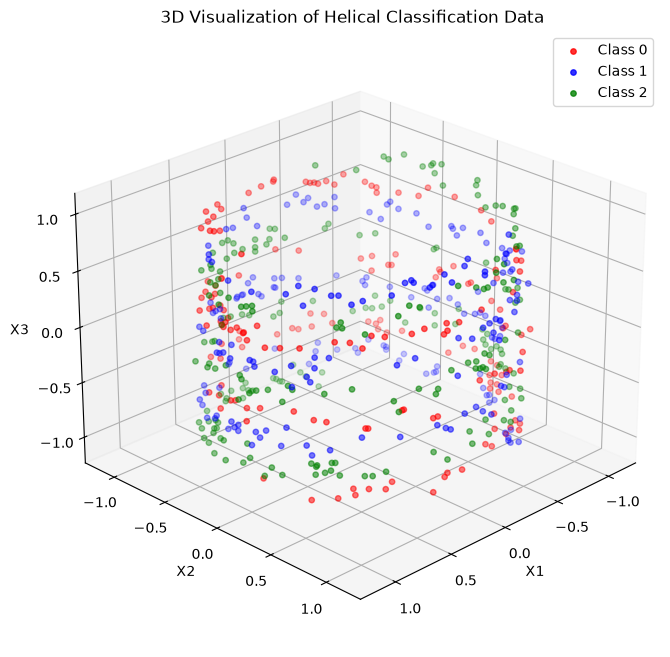

In [60]:


X_plot = X_train[:600]
y_plot = y_train[:600]

colors = ['red', 'blue', 'green', 'orange']

fig = plt.figure(figsize=(10, 8))



colors = ['red', 'blue', 'green', 'orange']


ax = fig.add_subplot(111, projection='3d')

for class_id in range(3):
    mask = y_plot == class_id

    ax.scatter(
        X_plot[mask, 0],
        X_plot[mask, 1],
        X_plot[mask, 2],
        color=colors[class_id],
        label=f'Class {class_id}',
        s=15,
        alpha=0.8
    )

ax.set_xlabel('X1')
ax.set_ylabel('X2')
ax.set_zlabel('X3')
ax.set_title('3D Visualization of Helical Classification Data')
ax.legend()

ax.view_init(elev=25, azim=45)


plt.show()


In [61]:

import torch.nn as nn


class MLP(nn.Module):
    """
    Fully connected neural network with a configurable
    number of hidden layers and neurons per layer.

    If n_hidden_layers = 0, the model is a single linear layer.
    The output consists of logits (no softmax).
    """

    def __init__(
        self,
        n_hidden_layers,
        width,
        n_classes,
        n_inputs=3,
        activation=nn.ReLU
    ):
        super().__init__()

        layers = []

        # Input layer to hidden layers
        for i in range(n_hidden_layers):
            in_features = n_inputs if i == 0 else width

            layers.append(nn.Linear(in_features, width))
            layers.append(activation())

        # Final output layer
        layers.append(nn.Linear(
            width if n_hidden_layers > 0 else n_inputs,
            n_classes
        ))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

    def count_parameters(model):
    #Number of trainable parameters.
     return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )



In [62]:
w = 16
K = 3

print("Hidden Layers | Parameters")
print("---------------------------")

for L in range(6):

    model = MLP(
        n_hidden_layers=L,
        width=w,
        n_classes=K
    )

    total_parameters = model.count_parameters()

    print(f"{L:^13} | {total_parameters}")

Hidden Layers | Parameters
---------------------------
      0       | 12
      1       | 115
      2       | 387
      3       | 659
      4       | 931
      5       | 1203


In [63]:

@torch.no_grad()
def accuracy(model, X, y):
    """Fraction of correctly classified points."""

    model.eval()

    logits = model(X)

    predictions = logits.argmax(dim=1)

    correct = (predictions == y).sum()

    return (correct / len(y)).item()


In [64]:




@torch.no_grad()
def accuracy(model, X, y):
    """Fraction of correctly classified points."""

    model.eval()

    logits = model(X)
    predictions = logits.argmax(dim=1)

    correct = (predictions == y).sum()

    return (correct / len(y)).item()


def train_model(
    model,
    X_train,
    y_train,
    X_test,
    y_test,
    epochs=100,
    lr=1e-2,
    batch_size=128,
    target_acc=0.9
):
    """
    Train model and return training history and training time.
    """

    # Loss function
    loss_fn = nn.CrossEntropyLoss()

    # Optimizer
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr
    )

    # Learning-rate scheduler
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        epochs
    )

    n = X_train.shape[0]

    # Store results
    hist = {
        "train_loss": [],
        "train_acc": [],
        "test_acc": [],
        "epochs_to_target": None
    }

    elapsed = 0.0

    for epoch in range(1, epochs + 1):

        model.train()

        # Start measuring training time
        t0 = time.perf_counter()

        # Shuffle training data
        perm = torch.randperm(n)

        epoch_loss = 0.0

        # Mini-batch training
        for i in range(0, n, batch_size):

            idx = perm[i:i + batch_size]

            X_batch = X_train[idx]
            y_batch = y_train[idx]

            # Forward pass
            logits = model(X_batch)

            # Calculate loss
            loss = loss_fn(logits, y_batch)

            # Backward pass
            optimizer.zero_grad()
            loss.backward()

            # Update parameters
            optimizer.step()

            # Accumulate loss weighted by batch size
            epoch_loss += loss.item() * len(idx)

        # Adjust learning rate
        scheduler.step()

        # Stop measuring training time
        elapsed += time.perf_counter() - t0

        # Calculate average loss for this epoch
        avg_loss = epoch_loss / n

        # Evaluate training and test accuracy
        train_acc = accuracy(model, X_train, y_train)
        test_acc = accuracy(model, X_test, y_test)

        # Store results
        hist["train_loss"].append(avg_loss)
        hist["train_acc"].append(train_acc)
        hist["test_acc"].append(test_acc)

        # Record the first epoch reaching target accuracy
        if (
            hist["epochs_to_target"] is None
            and train_acc >= target_acc
        ):
            hist["epochs_to_target"] = epoch

    # Store total training time
    hist["train_time"] = elapsed

    return hist


In [65]:
model = MLP(
    n_hidden_layers=3,
    width=16,
    n_classes=3
)

print(model)

MLP(
  (network): Sequential(
    (0): Linear(in_features=3, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=16, bias=True)
    (5): ReLU()
    (6): Linear(in_features=16, out_features=3, bias=True)
  )
)


In [66]:
print("Trainable parameters:", model.count_parameters())

Trainable parameters: 659


In [67]:
history = train_model(
    model,
    X_train,
    y_train,
    X_test,
    y_test,
    epochs=100,
    lr=0.01,
    batch_size=128,
    target_acc=0.9
)

In [68]:
print("Training time:", history["train_time"], "seconds")

print(
    "Epochs to reach target accuracy:",
    history["epochs_to_target"]
)

print("Final training accuracy:", history["train_acc"][-1])
print("Final test accuracy:", history["test_acc"][-1])

Training time: 0.8407513309884962 seconds
Epochs to reach target accuracy: 25
Final training accuracy: 0.9806666374206543
Final test accuracy: 0.9480000138282776


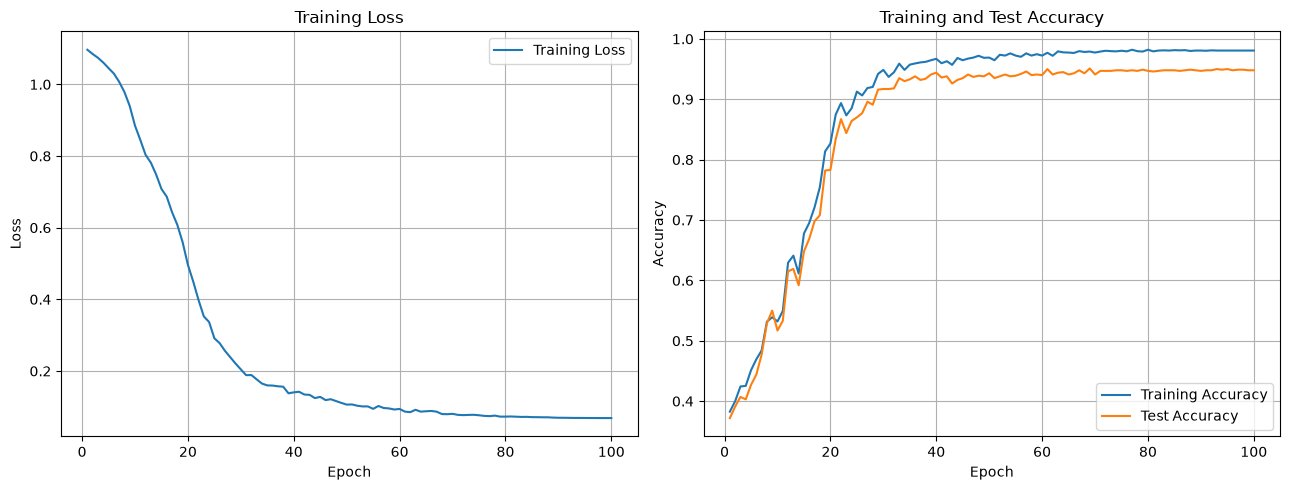

In [69]:


epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot training loss
axes[0].plot(
    epochs,
    history["train_loss"],
    label="Training Loss"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Training Loss")
axes[0].legend()
axes[0].grid(True)

# Plot training and test accuracy
axes[1].plot(
    epochs,
    history["train_acc"],
    label="Training Accuracy"
)

axes[1].plot(
    epochs,
    history["test_acc"],
    label="Test Accuracy"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Training and Test Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()
